# Interactive DIFT correspondence heatmap

给定两张图片 `src_img` 和 `trg_img`，在左图点击一个接触点 `src_ctpt`；右图会显示该点与目标图各位置的 DIFT cosine-similarity heatmap，并用红圈标出最大值位置 `trg_max_pt`。

实现参考：`/home/CNS2026002708/dift/demo.ipynb` 的点击交互，以及 `BiMo/code/Correspondence/sc_models/dift/get_cor.py` 的 DIFT 对应点计算方式。为减少计算量，notebook 会先把两张 object image 和 target mask 保形缩放到同一较小画布，再在该统一尺寸上完成点击、heatmap 与 2D-to-3D 映射。

## Environment

这台机器是 RTX 5060 (`sm_120`)。已检测到 `dift` 环境中的 `torch 2.1.2+cu121` 无法在该 GPU 上执行 CUDA kernel，而 `sam2` 环境的 `torch 2.11.0+cu128` 可以正常运行。因此本 notebook 建议选择 `sam2` kernel，并只补充 DIFT 可视化所需依赖：

```bash
conda activate sam2
python -m pip install diffusers transformers accelerate matplotlib ipympl trimesh viser
python -m ipykernel install --user --name sam2 --display-name 'Python (sam2)'
```

下面的 `SDFeatureHook` 复现 DIFT 的关键步骤：将图像加噪到 timestep `t=261`，从 Stable Diffusion U-Net 的 `up_blocks[1]` 提取特征，再进行逐像素余弦匹配。它使用 forward hook 代替旧版 DIFT 对 `diffusers` 内部 `UNet.forward` 的复制，从而可在现代 PyTorch/diffusers 上运行。

DIFT 论文/原仓库使用 `stabilityai/stable-diffusion-2-1`，但该仓库当前需要 Hugging Face 访问权限（本机未登录时返回 401）。本 notebook 默认使用可直接下载的 `stable-diffusion-v1-5/stable-diffusion-v1-5` 运行相同的 diffusion-feature 匹配流程；获得 SD-2.1 权限后，在参数单元格将 `MODEL_ID = OFFICIAL_DIFT_MODEL_ID` 即可回到原始模型。公开模型的 FP16 权重已缓存在本机，所以默认以 `MODEL_LOCAL_FILES_ONLY = True` 加载；换机器运行时将其改回 `False` 以首次下载。

## 1. Imports and configuration

将下面两个路径改成你的源图与目标图。两张 object image 与 target mask 会先保形缩放到相同的 `384 x 384` 画布；8 GB 显存默认使用 `384 / 2`，显存足够时可将 `INPUT_CANVAS_SIZE` 改为 `512` 或更高。

In [17]:
%matplotlib widget

import gc
import json
import os
import shutil
import sys
from pathlib import Path

# Direct HTTP is more reliable than Xet storage on this machine.
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from diffusers import DDIMScheduler, StableDiffusionPipeline

DIFT_REPO = Path('/home/CNS2026002708/dift')
SAM2_REPO = Path('/home/CNS2026002708/sam2')

# Input images and target-object assets.
# Previous example kept for reuse:
SRC_IMG_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs_sam2_outputs/masked_obj/french_press_1.png')
TRG_IMG_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs/laundry_detergent.jpg')
# TRG_MASKED_OBJ_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs_sam2_outputs/masked_obj/0517/watering_can_1.png')
# TRG_IMG_PATH = TRG_MASKED_OBJ_PATH
# TRG_MASK_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs_sam2_outputs/masks/0517/watering_can_1_mask.png')
# Source was masked from /home/CNS2026002708/BiMo/single_obj_imgs/0530/blue_bucket.jpg with SAM2.
# TRG_IMG_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs/0528/sun_screen.png')
# SRC_IMG_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs/0528/red_toothpasta.png')
# TRG_IMG_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs/hand_cream_1.jpg')

TRG_MASKED_OBJ_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs_sam2_outputs/masks/0528/red_toothpasta_mask.png')
TRG_DIFT_IMG_PATH = TRG_MASKED_OBJ_PATH  # DIFT matching and right-side click viewer use the masked target image.
TRG_MASK_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs/hand_cream_1.jpg')
TRG_OBJ_PATH = Path('/home/CNS2026002708/BiMo/single_obj_imgs/0530/white_basket.obj')
FLIP_SRC_HORIZONTAL = False
ROTATE_SRC_CCW_DEGREES = 0
USE_MASKED_OBJ_AS_MASK = False
SAM2_MODEL_CFG = 'configs/sam2.1/sam2.1_hiera_s.yaml'
SAM2_CHECKPOINT = Path('/home/CNS2026002708/sam2/checkpoints/sam2.1_hiera_small.pt')
NONBLACK_THRESHOLD = 8

# Original DIFT uses SD-2.1, which requires Hugging Face access on this machine.
OFFICIAL_DIFT_MODEL_ID = 'stabilityai/stable-diffusion-2-1'
PUBLIC_MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
MODEL_ID = PUBLIC_MODEL_ID  # Set to OFFICIAL_DIFT_MODEL_ID after `hf auth login`.

SRC_PROMPT = 'a photo of a transparent blue bucket'
TRG_PROMPT = 'a photo of a big white basket'
INPUT_CANVAS_SIZE = 384  # Resize both object views and the target mask to the same compact canvas.
IMG_SIZE = INPUT_CANVAS_SIZE  # Set both to 512 for a higher-resolution, higher-memory run.
ENSEMBLE_SIZE = 2
T = 261
UP_FT_INDEX = 1
HEATMAP_ALPHA = 0.48
MODEL_LOCAL_FILES_ONLY = True  # Public FP16 checkpoint is already cached on this machine.
LOW_VRAM_MODE = True  # Recommended for 8 GB GPUs: move only the active SD module to CUDA.
MAX_CONTROL_POINTS = 2  # Click up to two source control points before exporting heatmaps.
HEATMAP_OUTPUT_DIR = Path('/home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs')

assert torch.cuda.is_available(), 'DIFT SD feature extraction requires a CUDA GPU.'
DEVICE = 'cuda'
print('CUDA device:', torch.cuda.get_device_name(0))

CUDA device: NVIDIA GeForce RTX 5060


## 2. Optional: manually box target for SAM2 mask

如果自动 SAM2 mask 不准，先运行下面两个单元格。第一个单元格会显示 `TRG_IMG_PATH`，用鼠标左键拖一个框包住目标物体；第二个单元格会用这个 box prompt 调 SAM2，保存并覆盖 `TRG_MASK_PATH` 和 `TRG_MASKED_OBJ_PATH`。保存后再运行后面的 DIFT feature extraction。

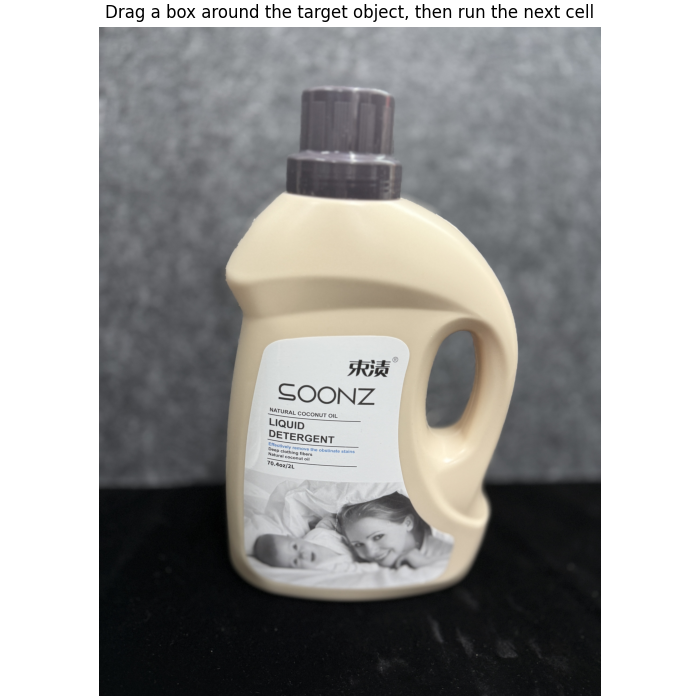

In [18]:
from matplotlib.widgets import RectangleSelector

manual_sam2_box = {'xyxy': None}
manual_sam2_image = Image.open(TRG_IMG_PATH).convert('RGB')
fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
ax.imshow(manual_sam2_image)
ax.set_title('Drag a box around the target object, then run the next cell')
ax.axis('off')

def _on_manual_sam2_box(eclick, erelease):
    x0, y0 = eclick.xdata, eclick.ydata
    x1, y1 = erelease.xdata, erelease.ydata
    if None in (x0, y0, x1, y1):
        return
    w, h = manual_sam2_image.size
    xyxy = np.array([
        np.clip(min(x0, x1), 0, w - 1),
        np.clip(min(y0, y1), 0, h - 1),
        np.clip(max(x0, x1), 0, w - 1),
        np.clip(max(y0, y1), 0, h - 1),
    ], dtype=np.float32)
    manual_sam2_box['xyxy'] = xyxy
    print('manual_sam2_box xyxy =', xyxy.tolist())

manual_sam2_selector = RectangleSelector(
    ax,
    _on_manual_sam2_box,
    useblit=True,
    button=[1],
    minspanx=5,
    minspany=5,
    spancoords='pixels',
    interactive=True,
)
plt.show()


Saved manual SAM2 mask: /home/CNS2026002708/BiMo/single_obj_imgs/hand_cream_1.jpg
Saved manual masked object: /home/CNS2026002708/BiMo/single_obj_imgs_sam2_outputs/masks/0528/red_toothpasta_mask.png
SAM2 scores: [0.8671875, 0.98828125, 0.98828125] chosen: 1


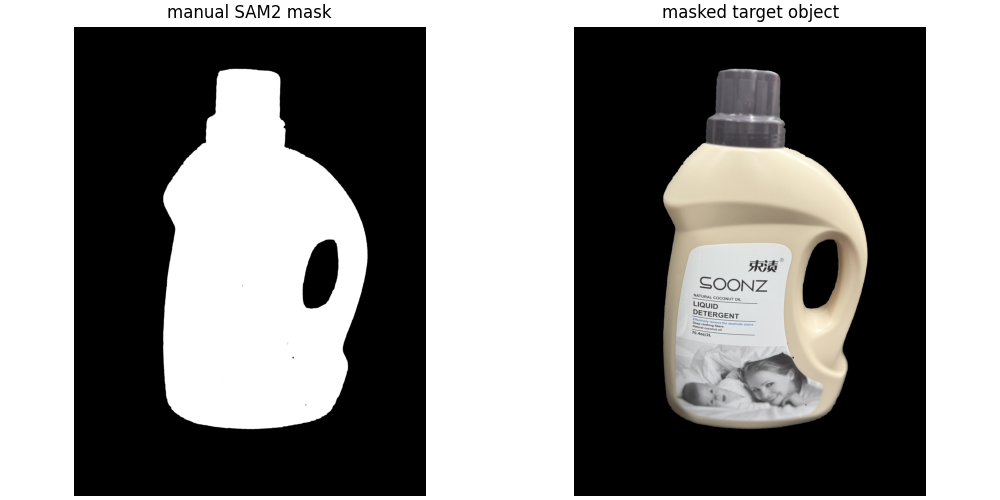

In [19]:
assert manual_sam2_box.get('xyxy') is not None, 'Run the previous cell and drag a box first.'
assert SAM2_CHECKPOINT.exists(), f'Missing SAM2 checkpoint: {SAM2_CHECKPOINT}'
if str(SAM2_REPO) not in sys.path:
    sys.path.insert(0, str(SAM2_REPO))

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

sam2_image = np.asarray(Image.open(TRG_IMG_PATH).convert('RGB')).copy()
sam2_model = build_sam2(SAM2_MODEL_CFG, str(SAM2_CHECKPOINT), device=DEVICE, apply_postprocessing=False)
sam2_predictor = SAM2ImagePredictor(sam2_model)
with torch.inference_mode(), torch.autocast('cuda', dtype=torch.bfloat16, enabled=torch.cuda.is_available()):
    sam2_predictor.set_image(sam2_image)
    masks, scores, _ = sam2_predictor.predict(
        box=manual_sam2_box['xyxy'][None, :],
        multimask_output=True,
    )
best_idx = int(np.argmax(scores))
mask = masks[best_idx].astype(bool)
mask_u8 = (mask.astype(np.uint8) * 255)

TRG_MASK_PATH.parent.mkdir(parents=True, exist_ok=True)
TRG_MASKED_OBJ_PATH.parent.mkdir(parents=True, exist_ok=True)
Image.fromarray(mask_u8, mode='L').save(TRG_MASK_PATH)
masked_rgb = sam2_image.copy()
masked_rgb[~mask] = 0
Image.fromarray(masked_rgb).save(TRG_MASKED_OBJ_PATH)

del sam2_predictor, sam2_model
gc.collect()
torch.cuda.empty_cache()
print('Saved manual SAM2 mask:', TRG_MASK_PATH)
print('Saved manual masked object:', TRG_MASKED_OBJ_PATH)
print('SAM2 scores:', scores.tolist(), 'chosen:', best_idx)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
axes[0].imshow(mask_u8, cmap='gray')
axes[0].set_title('manual SAM2 mask')
axes[0].axis('off')
axes[1].imshow(masked_rgb)
axes[1].set_title('masked target object')
axes[1].axis('off')
plt.show()


## 3. Load DIFT and extract features

该单元格耗时最长：它加载扩散模型并分别为两张图提取一次 feature。点击交互不会重复执行此步骤。

In [20]:
class SDFeatureHook:
    """DIFT-style SD feature extractor compatible with modern diffusers."""
    def __init__(self, sd_id='stabilityai/stable-diffusion-2-1', device='cuda', local_files_only=False, low_vram=True):
        self.device = torch.device(device)
        self.dtype = torch.float16 if self.device.type == 'cuda' else torch.float32
        self.low_vram = low_vram and self.device.type == 'cuda'
        self.pipe = StableDiffusionPipeline.from_pretrained(
            sd_id,
            torch_dtype=self.dtype,
            safety_checker=None,
            requires_safety_checker=False,
            variant='fp16',
            use_safetensors=True,
            local_files_only=local_files_only,
        )
        self.pipe.scheduler = DDIMScheduler.from_pretrained(
            sd_id, subfolder='scheduler', local_files_only=local_files_only
        )
        self.pipe.enable_attention_slicing()
        try:
            self.pipe.enable_xformers_memory_efficient_attention()
        except Exception as exc:
            print('xformers attention unavailable; continuing without it:', exc)
        if not self.low_vram:
            self.pipe.to(self.device)

    def _activate(self, module):
        if self.low_vram:
            module.to(self.device)

    def _offload(self, module):
        if self.low_vram:
            module.to('cpu')
            torch.cuda.empty_cache()

    @torch.no_grad()
    def forward(self, img_tensor, prompt='', t=261, up_ft_index=1, ensemble_size=2):
        if img_tensor.ndim == 3:
            img_tensor = img_tensor.unsqueeze(0)
        img_tensor = img_tensor.repeat(ensemble_size, 1, 1, 1).to(self.device, dtype=self.dtype)
        self._activate(self.pipe.text_encoder)
        try:
            prompt_output = self.pipe.encode_prompt(
                prompt=prompt,
                device=self.device,
                num_images_per_prompt=1,
                do_classifier_free_guidance=False,
            )
        finally:
            self._offload(self.pipe.text_encoder)
        prompt_embeds = prompt_output[0] if isinstance(prompt_output, tuple) else prompt_output
        prompt_embeds = prompt_embeds.repeat(ensemble_size, 1, 1).to(dtype=self.dtype)
        self._activate(self.pipe.vae)
        try:
            latents = self.pipe.vae.encode(img_tensor).latent_dist.sample() * self.pipe.vae.config.scaling_factor
        finally:
            self._offload(self.pipe.vae)
        timesteps = torch.full((ensemble_size,), t, dtype=torch.long, device=self.device)
        noisy_latents = self.pipe.scheduler.add_noise(latents, torch.randn_like(latents), timesteps)

        captured = {}
        class _FeatureCaptured(Exception):
            pass

        def store_feature(_module, _inputs, output):
            captured['feature'] = (output[0] if isinstance(output, tuple) else output).detach()
            # Original DIFT stops after the selected up block; skip later U-Net work.
            raise _FeatureCaptured

        self._activate(self.pipe.unet)
        handle = self.pipe.unet.up_blocks[up_ft_index].register_forward_hook(store_feature)
        try:
            try:
                self.pipe.unet(noisy_latents, timesteps, encoder_hidden_states=prompt_embeds, return_dict=False)
            except _FeatureCaptured:
                pass
        finally:
            handle.remove()
            self._offload(self.pipe.unet)
        return captured['feature'].mean(0, keepdim=True).float()

# This cell is safe to rerun: release a previous viewer/model/features before reloading SD.
if 'viewer' in globals() and getattr(viewer, 'fig', None) is not None:
    plt.close(viewer.fig)
for stale_name in ('viewer', 'dift', 'src_ft_dense', 'trg_ft_dense', 'src_ft', 'trg_ft'):
    if stale_name in globals():
        del globals()[stale_name]
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    torch.cuda.ipc_collect()

def fit_to_canvas(image, canvas_size, fill, resample=Image.Resampling.LANCZOS):
    """Preserve aspect ratio while putting images/masks in one shared square coordinate system."""
    scale = min(canvas_size / image.width, canvas_size / image.height)
    fitted_size = (max(1, int(round(image.width * scale))), max(1, int(round(image.height * scale))))
    fitted = image.resize(fitted_size, resample)
    canvas = Image.new(image.mode, (canvas_size, canvas_size), fill)
    offset = ((canvas_size - fitted_size[0]) // 2, (canvas_size - fitted_size[1]) // 2)
    canvas.paste(fitted, offset)
    return canvas

raw_src_img = Image.open(SRC_IMG_PATH).convert('RGB')
raw_trg_ref_img = Image.open(TRG_IMG_PATH).convert('RGB')
if not TRG_DIFT_IMG_PATH.exists() or not TRG_MASK_PATH.exists():
    raise FileNotFoundError(
        f'Missing target mask assets. First run the manual SAM2 box cells above to create:\n'
        f'  mask: {TRG_MASK_PATH}\n'
        f'  masked target: {TRG_MASKED_OBJ_PATH}'
    )
raw_trg_img = Image.open(TRG_DIFT_IMG_PATH).convert('RGB')
src_img = fit_to_canvas(raw_src_img, INPUT_CANVAS_SIZE, fill=(255, 255, 255))
trg_img = fit_to_canvas(raw_trg_img, INPUT_CANVAS_SIZE, fill=(0, 0, 0))
if FLIP_SRC_HORIZONTAL:
    src_img = src_img.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
if ROTATE_SRC_CCW_DEGREES == 90:
    src_img = src_img.transpose(Image.Transpose.ROTATE_90)
elif ROTATE_SRC_CCW_DEGREES == 180:
    src_img = src_img.transpose(Image.Transpose.ROTATE_180)
elif ROTATE_SRC_CCW_DEGREES == 270:
    src_img = src_img.transpose(Image.Transpose.ROTATE_270)
elif ROTATE_SRC_CCW_DEGREES != 0:
    src_img = src_img.rotate(ROTATE_SRC_CCW_DEGREES, resample=Image.Resampling.BICUBIC, expand=False, fillcolor=(255, 255, 255))
if USE_MASKED_OBJ_AS_MASK:
    masked_rgb = np.asarray(trg_img)
    trg_mask_img = Image.fromarray((np.max(masked_rgb, axis=2) > NONBLACK_THRESHOLD).astype(np.uint8) * 255)
else:
    raw_trg_mask = Image.open(TRG_MASK_PATH).convert('L').resize(raw_trg_img.size, Image.Resampling.NEAREST)
    trg_mask_img = fit_to_canvas(raw_trg_mask, INPUT_CANVAS_SIZE, fill=0, resample=Image.Resampling.NEAREST)
trg_mask = np.asarray(trg_mask_img) > 0
print('original sizes:', raw_src_img.size, raw_trg_ref_img.size)
print('shared input canvas:', src_img.size, trg_img.size)
print('Loading diffusion feature model:', MODEL_ID)
dift = SDFeatureHook(sd_id=MODEL_ID, device=DEVICE, local_files_only=MODEL_LOCAL_FILES_ONLY, low_vram=LOW_VRAM_MODE)
print('src_img:', SRC_IMG_PATH, src_img.size)
print('trg_img original:', TRG_IMG_PATH, raw_trg_ref_img.size)
print('trg_img used for DIFT/viewer:', TRG_DIFT_IMG_PATH, trg_img.size)
print('trg_mask source:', TRG_MASKED_OBJ_PATH if USE_MASKED_OBJ_AS_MASK else TRG_MASK_PATH)
print('trg_mask foreground pixels=', int(trg_mask.sum()))
print('source horizontally mirrored:', FLIP_SRC_HORIZONTAL)
print('source counter-clockwise rotation:', ROTATE_SRC_CCW_DEGREES, 'degrees')

def image_to_dift_tensor(image, image_size):
    resized = image.resize((image_size, image_size), Image.Resampling.BILINEAR)
    image_array = np.asarray(resized, dtype=np.float32) / 127.5 - 1.0
    return torch.from_numpy(image_array).permute(2, 0, 1).contiguous()

def extract_dift_feature(image, prompt):
    tensor = image_to_dift_tensor(image, IMG_SIZE)
    return dift.forward(
        tensor,
        prompt=prompt,
        t=T,
        up_ft_index=UP_FT_INDEX,
        ensemble_size=ENSEMBLE_SIZE,
    )

with torch.no_grad():
    print('Extracting source DIFT feature...')
    src_ft = extract_dift_feature(src_img, SRC_PROMPT)
    print('Extracting target DIFT feature...')
    trg_ft = extract_dift_feature(trg_img, TRG_PROMPT)

    # Work on the same square image coordinate system used by DIFT extraction.
    src_ft_dense = F.interpolate(src_ft, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=True)
    trg_ft_dense = F.interpolate(trg_ft, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=True)
    trg_ft_dense = F.normalize(trg_ft_dense, p=2, dim=1)

del src_ft, trg_ft, dift
gc.collect()
torch.cuda.empty_cache()
print('Ready. DIFT feature shape:', tuple(src_ft_dense.shape))
print('Diffusion pipeline released; only dense matching features remain allocated.')

original sizes: (3072, 4096) (3072, 4096)
shared input canvas: (384, 384) (384, 384)
Loading diffusion feature model: stable-diffusion-v1-5/stable-diffusion-v1-5


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

xformers attention unavailable; continuing without it: Refer to https://github.com/facebookresearch/xformers for more information on how to install xformers
src_img: /home/CNS2026002708/BiMo/single_obj_imgs_sam2_outputs/masked_obj/french_press_1.png (384, 384)
trg_img original: /home/CNS2026002708/BiMo/single_obj_imgs/laundry_detergent.jpg (3072, 4096)
trg_img used for DIFT/viewer: /home/CNS2026002708/BiMo/single_obj_imgs_sam2_outputs/masks/0528/red_toothpasta_mask.png (384, 384)
trg_mask source: /home/CNS2026002708/BiMo/single_obj_imgs/hand_cream_1.jpg
trg_mask foreground pixels= 35581
source horizontally mirrored: False
source counter-clockwise rotation: 0 degrees
Extracting source DIFT feature...
Extracting target DIFT feature...
Ready. DIFT feature shape: (1, 1280, 384, 384)
Diffusion pipeline released; only dense matching features remain allocated.


## 3. Mask-constrained matching and interactive viewer

执行下一单元格后，在左侧 `source image` 上最多点击两个点。每个点的 DIFT 相似度都会单独保存到 `viewer.matches`；交互图仍由 `trg_mask` 限制显示区域与最大点搜索。需要重新选点时运行 `viewer.clear_points()`。步骤 5 会调用 `viewer.save_2d_heatmaps()` 导出每个点及合并结果的无 mask 二维热图。

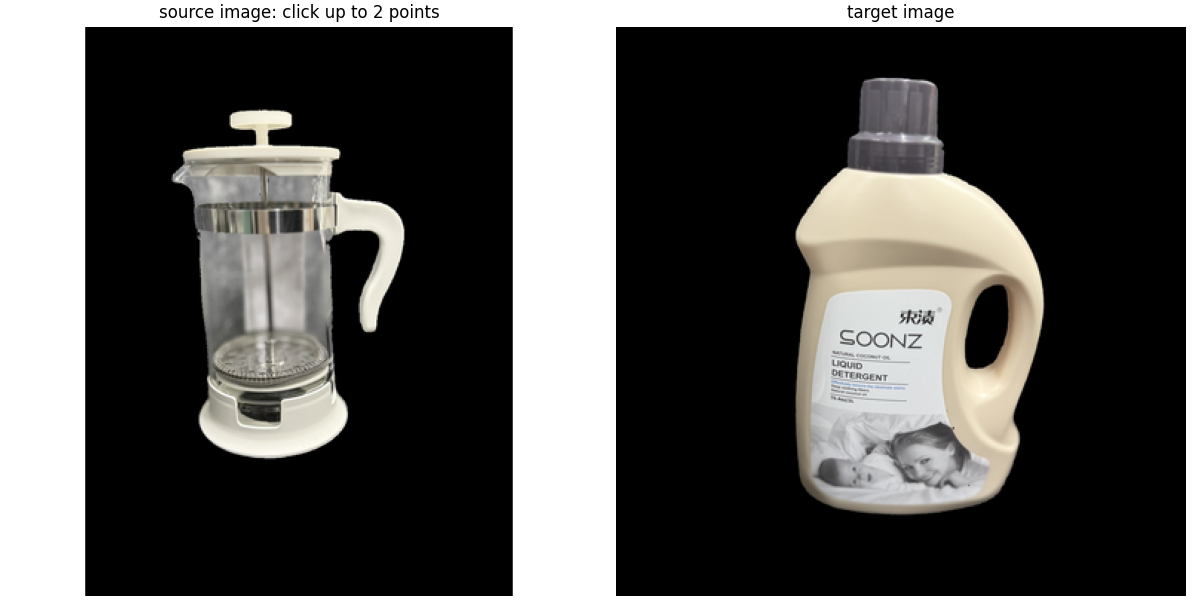

In [21]:
class InteractiveDIFTViewer:
    def __init__(self, src_image, trg_image, src_feature, trg_feature, model_size, target_mask=None, alpha=0.48):
        self.src_img = src_image
        self.trg_img = trg_image
        self.src_feature = src_feature
        self.trg_feature = trg_feature
        self.model_size = model_size
        self.target_mask = target_mask
        self.alpha = alpha
        self.max_control_points = MAX_CONTROL_POINTS
        self.matches = []
        self.heatmap = None  # Latest heatmap, retained for compatibility.
        self.fig = None
        self.axes = None

    @staticmethod
    def _scale_coordinate(value, source_length, target_length):
        if source_length <= 1:
            return 0
        return int(np.clip(round(value * (target_length - 1) / (source_length - 1)), 0, target_length - 1))

    @torch.no_grad()
    def _compute_match(self, src_ctpt):
        x, y = (int(round(src_ctpt[0])), int(round(src_ctpt[1])))
        src_w, src_h = self.src_img.size
        trg_w, trg_h = self.trg_img.size
        x = int(np.clip(x, 0, src_w - 1))
        y = int(np.clip(y, 0, src_h - 1))

        model_x = self._scale_coordinate(x, src_w, self.model_size)
        model_y = self._scale_coordinate(y, src_h, self.model_size)
        src_vec = self.src_feature[:, :, model_y, model_x]
        src_vec = F.normalize(src_vec, p=2, dim=1)[:, :, None, None]
        cos_map = (src_vec * self.trg_feature).sum(dim=1, keepdim=True)
        cos_map = F.interpolate(cos_map, size=(trg_h, trg_w), mode='bilinear', align_corners=True)
        heatmap = cos_map[0, 0].detach().cpu().numpy()

        search_map = heatmap if self.target_mask is None else np.where(self.target_mask, heatmap, -np.inf)
        max_y, max_x = np.unravel_index(np.argmax(search_map), search_map.shape)
        return {'src_ctpt': (x, y), 'trg_max_pt': (int(max_x), int(max_y)),
                'max_similarity': float(heatmap[max_y, max_x]), 'heatmap': heatmap}

    def add_point(self, src_ctpt):
        if len(self.matches) >= self.max_control_points:
            print(f'Already collected {self.max_control_points} points. Run viewer.clear_points() to start over.')
            return None
        result = self._compute_match(src_ctpt)
        self.matches.append(result)
        self.heatmap = result['heatmap']
        return result

    def clear_points(self):
        self.matches.clear()
        self.heatmap = None
        self._draw()
        print('Cleared points. Click up to two new source control points.')

    @staticmethod
    def _normalize_heatmap(heatmap):
        minimum = float(heatmap.min())
        spread = float(heatmap.max() - minimum)
        return (heatmap - minimum) / max(spread, 1e-8)

    def _draw(self):
        ax_src, ax_trg = self.axes
        ax_src.clear()
        ax_trg.clear()
        ax_src.imshow(self.src_img)
        ax_src.set_title(f'source image: click up to {self.max_control_points} points')
        ax_src.axis('off')
        ax_trg.imshow(self.trg_img)
        ax_trg.set_title('target image')
        ax_trg.axis('off')

        colors = ('red', 'cyan')
        if self.matches:
            for index, result in enumerate(self.matches):
                color = colors[index % len(colors)]
                ax_src.scatter(*result['src_ctpt'], c=color, s=85, marker='o', edgecolors='white', linewidths=1.2)
                ax_src.text(result['src_ctpt'][0] + 4, result['src_ctpt'][1] + 4, str(index + 1), color=color, fontsize=12)
            normalized = np.maximum.reduce([self._normalize_heatmap(result['heatmap']) for result in self.matches])
            if self.target_mask is not None:
                normalized = np.ma.masked_where(~self.target_mask, normalized)
            ax_trg.imshow(normalized, cmap='viridis', alpha=self.alpha, vmin=0.0, vmax=1.0)
            for index, result in enumerate(self.matches):
                color = colors[index % len(colors)]
                ax_trg.scatter(*result['trg_max_pt'], c=color, s=105, marker='o', edgecolors='white', linewidths=1.4)
                ax_trg.text(result['trg_max_pt'][0] + 4, result['trg_max_pt'][1] + 4, str(index + 1), color=color, fontsize=12)
            ax_trg.set_title(f'target heatmaps: {len(self.matches)} point(s)')
        self.fig.canvas.draw_idle()

    def _onclick(self, event):
        if event.inaxes is not self.axes[0] or event.xdata is None or event.ydata is None:
            return
        result = self.add_point((event.xdata, event.ydata))
        if result is None:
            return
        self._draw()
        print(f'point {len(self.matches)}: src_ctpt={result["src_ctpt"]} -> trg_max_pt={result["trg_max_pt"]}, cosine={result["max_similarity"]:.4f}')

    def save_2d_heatmaps(self, output_dir=HEATMAP_OUTPUT_DIR, dpi=180):
        assert self.matches, 'Click at least one source point before exporting.'
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        saved_paths = []

        # Always save the exact mask/image assets used in this run so the output folder is reusable.
        canvas_tag = f'{self.trg_img.width}x{self.trg_img.height}'
        export_mask = self.target_mask if self.target_mask is not None else np.ones((self.trg_img.height, self.trg_img.width), dtype=bool)
        target_mask_resized_path = output_dir / f'target_mask_resized_{canvas_tag}.png'
        target_masked_img_resized_path = output_dir / f'target_masked_img_resized_{canvas_tag}.png'
        source_img_resized_path = output_dir / f'source_img_resized_{self.src_img.width}x{self.src_img.height}.png'
        Image.fromarray(export_mask.astype(np.uint8) * 255, mode='L').save(target_mask_resized_path)
        self.trg_img.save(target_masked_img_resized_path)
        self.src_img.save(source_img_resized_path)
        saved_paths.extend([target_mask_resized_path, target_masked_img_resized_path, source_img_resized_path])
        if Path(TRG_MASK_PATH).exists():
            target_mask_original_path = output_dir / 'target_mask_original.png'
            shutil.copy2(TRG_MASK_PATH, target_mask_original_path)
            saved_paths.append(target_mask_original_path)
        if Path(TRG_MASKED_OBJ_PATH).exists():
            target_masked_img_original_path = output_dir / 'target_masked_img_original.png'
            shutil.copy2(TRG_MASKED_OBJ_PATH, target_masked_img_original_path)
            saved_paths.append(target_masked_img_original_path)

        heatmaps = np.stack([result['heatmap'].astype(np.float32) for result in self.matches], axis=0)
        normalized_heatmaps = np.stack([self._normalize_heatmap(result['heatmap']).astype(np.float32) for result in self.matches], axis=0)
        src_points = np.array([result['src_ctpt'] for result in self.matches], dtype=np.int32)
        trg_points = np.array([result['trg_max_pt'] for result in self.matches], dtype=np.int32)
        max_similarity = np.array([result['max_similarity'] for result in self.matches], dtype=np.float32)
        values_path = output_dir / 'heatmap_values_all.npz'
        np.savez_compressed(values_path, heatmaps=heatmaps, normalized_heatmaps=normalized_heatmaps, target_mask=export_mask, src_points=src_points, trg_points=trg_points, max_similarity=max_similarity)
        saved_paths.append(values_path)
        manifest = {
            'src_img_path': str(SRC_IMG_PATH),
            'trg_img_path': str(TRG_IMG_PATH),
            'trg_dift_img_path': str(TRG_DIFT_IMG_PATH),
            'trg_mask_path': str(TRG_MASK_PATH),
            'trg_masked_obj_path': str(TRG_MASKED_OBJ_PATH),
            'input_canvas_size': int(INPUT_CANVAS_SIZE),
            'img_size': int(IMG_SIZE),
            'model_id': MODEL_ID,
            'src_prompt': SRC_PROMPT,
            'trg_prompt': TRG_PROMPT,
            'saved_assets': {
                'target_mask_resized': target_mask_resized_path.name,
                'target_masked_img_resized': target_masked_img_resized_path.name,
                'source_img_resized': source_img_resized_path.name,
                'heatmap_values': values_path.name,
            },
            'matches': [
                {'index': i, 'src_ctpt': list(result['src_ctpt']), 'trg_max_pt': list(result['trg_max_pt']), 'max_similarity': float(result['max_similarity'])}
                for i, result in enumerate(self.matches, start=1)
            ],
        }
        manifest_path = output_dir / 'run_manifest.json'
        manifest_path.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
        saved_paths.append(manifest_path)

        def _draw_on_masked_target(normalized, title, filename, points=None):
            shown = normalized
            if self.target_mask is not None:
                shown = np.ma.masked_where(~self.target_mask, shown)
            fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
            fig.patch.set_facecolor('white')
            ax.imshow(self.trg_img)
            ax.imshow(shown, cmap='turbo', alpha=self.alpha, vmin=0.0, vmax=1.0)
            if points:
                for label, point, color in points:
                    ax.scatter(*point, c=color, s=55, edgecolors='white', linewidths=0.8)
                    ax.text(point[0] + 4, point[1] + 4, label, color=color, fontsize=12)
            ax.set_title(title)
            ax.axis('off')
            path = output_dir / filename
            fig.savefig(path, dpi=dpi, facecolor='white')
            plt.close(fig)
            saved_paths.append(path)

        for index, result in enumerate(self.matches, start=1):
            normalized_single = self._normalize_heatmap(result['heatmap'])
            fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
            fig.patch.set_facecolor('white')
            ax.imshow(normalized_single, cmap='turbo', vmin=0.0, vmax=1.0)
            ax.scatter(*result['trg_max_pt'], c='red', s=55, edgecolors='white', linewidths=0.8)
            ax.set_title(f'2D heatmap no mask | point {index}')
            ax.axis('off')
            path = output_dir / f'ctpt_{index:02d}_2d_heatmap_no_mask.png'
            fig.savefig(path, dpi=dpi, facecolor='white')
            plt.close(fig)
            saved_paths.append(path)
            _draw_on_masked_target(
                normalized_single,
                f'2D heatmap on masked target | point {index} | plain',
                f'ctpt_{index:02d}_2d_heatmap_on_masked_trg_plain.png',
            )
            _draw_on_masked_target(
                normalized_single,
                f'2D heatmap on masked target | point {index} | marked',
                f'ctpt_{index:02d}_2d_heatmap_on_masked_trg_marked.png',
                points=[(str(index), result['trg_max_pt'], 'red')],
            )
        if len(self.matches) > 1:
            combined = np.maximum.reduce([self._normalize_heatmap(result['heatmap']) for result in self.matches])
            fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
            fig.patch.set_facecolor('white')
            ax.imshow(combined, cmap='turbo', vmin=0.0, vmax=1.0)
            for index, result in enumerate(self.matches, start=1):
                ax.scatter(*result['trg_max_pt'], s=55, edgecolors='white', linewidths=0.8, label=f'point {index}')
            ax.legend(loc='lower right')
            ax.set_title('2D heatmaps no mask | combined maximum')
            ax.axis('off')
            path = output_dir / 'ctpt_combined_2d_heatmap_no_mask.png'
            fig.savefig(path, dpi=dpi, facecolor='white')
            plt.close(fig)
            saved_paths.append(path)
            combined_points = [(str(index), result['trg_max_pt'], ('red', 'cyan')[(index - 1) % 2]) for index, result in enumerate(self.matches, start=1)]
            _draw_on_masked_target(
                combined,
                '2D heatmaps on masked target | combined maximum | plain',
                'ctpt_combined_2d_heatmap_on_masked_trg_plain.png',
            )
            _draw_on_masked_target(
                combined,
                '2D heatmaps on masked target | combined maximum | marked',
                'ctpt_combined_2d_heatmap_on_masked_trg_marked.png',
                points=combined_points,
            )
        return saved_paths

    def show(self, fig_size=6):
        self.fig, self.axes = plt.subplots(1, 2, figsize=(fig_size * 2, fig_size), constrained_layout=True)
        self._draw()
        self.fig.canvas.mpl_connect('button_press_event', self._onclick)
        plt.show()
        return self

viewer = InteractiveDIFTViewer(
    src_img, trg_img, src_ft_dense, trg_ft_dense, IMG_SIZE, target_mask=trg_mask, alpha=HEATMAP_ALPHA
).show(fig_size=6)

In [ ]:
viewer.clear_points()

## 4. Export 2D Heatmaps Without Mesh

点完 `src_img` 上的一个或两个点后，直接运行下面这个 cell。它只保存 2D heatmap、masked target overlay、combined map、mask、manifest 和 heatmap 数值，不需要 `TRG_OBJ_PATH` 或任何 3D mesh。

In [22]:
saved_2d_paths = viewer.save_2d_heatmaps(HEATMAP_OUTPUT_DIR)
print('Saved 2D heatmaps and reusable mask/assets:')
for path in saved_2d_paths:
    print(' ', path)

Saved 2D heatmaps and reusable mask/assets:
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/target_mask_resized_384x384.png
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/target_masked_img_resized_384x384.png
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/source_img_resized_384x384.png
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/target_mask_original.png
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/target_masked_img_original.png
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/heatmap_values_all.npz
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/run_manifest.json
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/ctpt_01_2d_heatmap_no_mask.png
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/ctpt_01_2d_heatmap_on_masked_trg_plain.png
  /home/CNS2026002708/BiMo/code/Correspondence/heatmap_outputs/ctpt_01_2d_heatmap_on_masked_trg_marked.png
  /home/CN

## 5. Optional: Orient the OBJ to the masked target silhouette

`Ctpts/ctpts_to_3d.py` 在 BiMo 数据流程中使用相机 depth/XYZA 做严格的 2D-to-3D 回投。本节没有相机 pose/depth，因此先解决朝向：从 OBJ 表面降采样 `8192` 点，随机旋转点云，并把投影 silhouette 与 masked target object 比较。

下面单元格只输出候选方向图片，不执行最终 mesh scale 或 3D heatmap。候选预览为了比较 silhouette 会临时 fit 到 mask bbox；你确认方向编号后，下一单元格才应用该姿态、进行映射并启动 Viser。没有 mesh 时跳过本节即可，2D combined map 已经在上一个 cell 保存。

In [ ]:
import cv2
import trimesh

NUM_PTS = 8192
POINT_SEED = 0
ORIENTATION_TRIALS = 400
ORIENTATION_TOP_K = 6
ORIENTATION_SEED = 10
SEARCH_MAX_DIM = 320

def load_obj_as_mesh(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'Set TRG_OBJ_PATH to an existing .obj file: {path}')
    loaded = trimesh.load(str(path), force='mesh', process=False)
    if isinstance(loaded, trimesh.Scene):
        meshes = [g for g in loaded.geometry.values() if isinstance(g, trimesh.Trimesh)]
        loaded = trimesh.util.concatenate(meshes)
    if loaded.vertices.size == 0 or loaded.faces.size == 0:
        raise ValueError(f'OBJ has no surface triangles: {path}')
    return loaded

def surface_sample(mesh, num_pts, seed=0):
    state = np.random.get_state()
    np.random.seed(seed)
    try:
        points, _ = trimesh.sample.sample_surface(mesh, int(num_pts))
    finally:
        np.random.set_state(state)
    return points.astype(np.float32)

def mask_bbox(mask):
    ys, xs = np.nonzero(mask)
    return np.array([xs.min(), ys.min()], dtype=np.float32), np.array([xs.max(), ys.max()], dtype=np.float32)

def random_rotation_matrix(rng):
    u1, u2, u3 = rng.random(3)
    q = np.array([
        np.sqrt(1 - u1) * np.sin(2 * np.pi * u2),
        np.sqrt(1 - u1) * np.cos(2 * np.pi * u2),
        np.sqrt(u1) * np.sin(2 * np.pi * u3),
        np.sqrt(u1) * np.cos(2 * np.pi * u3),
    ], dtype=np.float32)  # x, y, z, w
    x, y, z, w = q
    return np.array([
        [1 - 2*y*y - 2*z*z, 2*x*y - 2*z*w, 2*x*z + 2*y*w],
        [2*x*y + 2*z*w, 1 - 2*x*x - 2*z*z, 2*y*z - 2*x*w],
        [2*x*z - 2*y*w, 2*y*z + 2*x*w, 1 - 2*x*x - 2*y*y],
    ], dtype=np.float32)

def temporarily_fit_projection(points, rotation, mask):
    rotated = points @ rotation.T
    projected = rotated[:, :2].copy()
    projected[:, 1] *= -1.0
    proj_center = 0.5 * (projected.min(0) + projected.max(0))
    proj_extent = np.maximum(projected.max(0) - projected.min(0), 1e-8)
    bbox_lo, bbox_hi = mask_bbox(mask)
    mask_center = 0.5 * (bbox_lo + bbox_hi)
    scale = float(np.min((bbox_hi - bbox_lo) / proj_extent))
    pixels_xy = (projected - proj_center) * scale + mask_center
    return rotated, pixels_xy, scale

def rasterize_projection(pixels_xy, image_shape, max_dim=320):
    h, w = image_shape
    ratio = min(1.0, float(max_dim) / max(h, w))
    out_w, out_h = max(1, round(w * ratio)), max(1, round(h * ratio))
    pixels = np.rint(pixels_xy * ratio).astype(np.int32)
    valid = (pixels[:, 0] >= 0) & (pixels[:, 0] < out_w) & (pixels[:, 1] >= 0) & (pixels[:, 1] < out_h)
    silhouette = np.zeros((out_h, out_w), dtype=np.uint8)
    silhouette[pixels[valid, 1], pixels[valid, 0]] = 1
    silhouette = cv2.dilate(silhouette, np.ones((5, 5), np.uint8), iterations=1).astype(bool)
    return silhouette, (out_w, out_h)

def silhouette_iou(pixels_xy, mask):
    predicted, out_size = rasterize_projection(pixels_xy, mask.shape, SEARCH_MAX_DIM)
    target = cv2.resize(mask.astype(np.uint8), out_size, interpolation=cv2.INTER_NEAREST).astype(bool)
    intersection = np.logical_and(predicted, target).sum()
    union = np.logical_or(predicted, target).sum()
    return float(intersection / max(union, 1))

trg_mesh = load_obj_as_mesh(TRG_OBJ_PATH)
trg_surface_points = surface_sample(trg_mesh, NUM_PTS, POINT_SEED)
trg_surface_points -= trg_surface_points.mean(axis=0, keepdims=True)
rng = np.random.default_rng(ORIENTATION_SEED)
orientation_candidates = []
rotations = [np.eye(3, dtype=np.float32)] + [random_rotation_matrix(rng) for _ in range(ORIENTATION_TRIALS)]
for rotation in rotations:
    rotated, pixels_xy, preview_scale = temporarily_fit_projection(trg_surface_points, rotation, trg_mask)
    orientation_candidates.append({
        'rotation': rotation, 'rotated_points': rotated, 'pixels_xy': pixels_xy,
        'preview_scale': preview_scale, 'score': silhouette_iou(pixels_xy, trg_mask),
    })
orientation_candidates.sort(key=lambda item: item['score'], reverse=True)
orientation_candidates = orientation_candidates[:ORIENTATION_TOP_K]

preview_ids = np.linspace(0, NUM_PTS - 1, min(NUM_PTS, 4000)).astype(np.int64)
fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
for candidate_id, (ax, candidate) in enumerate(zip(axes.flat, orientation_candidates)):
    ax.imshow(trg_img)
    ax.imshow(trg_mask, cmap='Greens', alpha=0.16)
    ax.scatter(candidate['pixels_xy'][preview_ids, 0], candidate['pixels_xy'][preview_ids, 1], s=2, c='red', alpha=0.40)
    ax.set_title(f'candidate {candidate_id}: silhouette IoU={candidate["score"]:.3f}')
    ax.axis('off')
plt.show()
print('Only orientation candidates were produced. No final scale or heatmap mapping has been applied.')
print('Choose a candidate id from the preview, then set SELECTED_ORIENTATION_ID in the next cell.')

### Confirm orientation, then map the heatmap in 3D

先根据上方候选图把 `SELECTED_ORIENTATION_ID` 设置为确认正确的编号，然后运行本单元格。它会导出每个 control point 的无 mask 2D heatmap 与白底 3D heatmap PNG，并在 Viser 中分别建立 `ctpt_01`、`ctpt_02` 点云。输出默认保存到 `HEATMAP_OUTPUT_DIR`。

In [ ]:
import viser

SELECTED_ORIENTATION_ID = 0  # Replace with a confirmed candidate id, for example: 0
VISER_PORT = 8080
VISER_POINT_SIZE = 0.012

import socket

assert viewer.matches, 'Click one or two source points in Step 3 first.'
assert SELECTED_ORIENTATION_ID is not None, 'Inspect the orientation preview first, then set SELECTED_ORIENTATION_ID.'
assert 0 <= SELECTED_ORIENTATION_ID < len(orientation_candidates), 'Candidate id is out of range.'
HEATMAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
saved_paths = viewer.save_2d_heatmaps(HEATMAP_OUTPUT_DIR)
selected_orientation = orientation_candidates[SELECTED_ORIENTATION_ID]
oriented_points = selected_orientation['rotated_points']
mesh_pixels_xy = selected_orientation['pixels_xy']
mesh_scale_to_image = selected_orientation['preview_scale']
mesh_pixels_ij = np.rint(mesh_pixels_xy).astype(np.int32)
mesh_pixels_ij[:, 0] = np.clip(mesh_pixels_ij[:, 0], 0, trg_mask.shape[1] - 1)
mesh_pixels_ij[:, 1] = np.clip(mesh_pixels_ij[:, 1], 0, trg_mask.shape[0] - 1)
mesh_inside_mask = trg_mask[mesh_pixels_ij[:, 1], mesh_pixels_ij[:, 0]]
def full_heat_colors(normalized):
    return (plt.get_cmap('turbo')(np.clip(normalized, 0.0, 1.0))[:, :3] * 255).astype(np.uint8)

scaled_points = oriented_points * mesh_scale_to_image
viser_points = scaled_points / max(float(np.max(np.ptp(scaled_points, axis=0))), 1e-8)
valid_indices = np.flatnonzero(mesh_inside_mask)
assert valid_indices.size > 0, 'Confirmed projection has no points in the target mask.'

if 'viser_server' in globals():
    try:
        viser_server.stop()
    except Exception:
        pass
viser_server = viser.ViserServer(port=VISER_PORT)
if hasattr(viser_server.scene, 'set_up_direction'):
    viser_server.scene.set_up_direction('+z')

for index, result in enumerate(viewer.matches, start=1):
    mesh_heat_values = result['heatmap'][mesh_pixels_ij[:, 1], mesh_pixels_ij[:, 0]].astype(np.float32)
    mesh_heat_full = (mesh_heat_values - float(mesh_heat_values.min())) / max(float(np.ptp(mesh_heat_values)), 1e-8)
    full_preview_colors = full_heat_colors(mesh_heat_full)
    best_idx = valid_indices[np.argmax(mesh_heat_values[valid_indices])]

    fig_white, ax_white = plt.subplots(figsize=(6, 6), constrained_layout=True)
    fig_white.patch.set_facecolor('white')
    ax_white.set_facecolor('white')
    ax_white.scatter(mesh_pixels_xy[:, 0], mesh_pixels_xy[:, 1], c=full_preview_colors / 255.0, s=4, linewidths=0)
    ax_white.scatter(mesh_pixels_xy[best_idx, 0], mesh_pixels_xy[best_idx, 1], c='red', s=45, edgecolors='black', linewidths=0.7)
    ax_white.set_xlim(0, trg_img.width)
    ax_white.set_ylim(trg_img.height, 0)
    ax_white.set_aspect('equal')
    ax_white.set_title(f'3D projection no mask | point {index}')
    ax_white.axis('off')
    path = HEATMAP_OUTPUT_DIR / f'ctpt_{index:02d}_3d_projection_no_mask.png'
    fig_white.savefig(path, dpi=180, facecolor='white')
    plt.show()
    saved_paths.append(path)

    fig_3d = plt.figure(figsize=(7, 6), constrained_layout=True)
    fig_3d.patch.set_facecolor('white')
    ax_3d = fig_3d.add_subplot(111, projection='3d')
    ax_3d.set_facecolor('white')
    ax_3d.scatter(viser_points[:, 0], viser_points[:, 1], viser_points[:, 2], c=full_preview_colors / 255.0, s=4, depthshade=False)
    ax_3d.scatter(viser_points[best_idx:best_idx + 1, 0], viser_points[best_idx:best_idx + 1, 1], viser_points[best_idx:best_idx + 1, 2], c='red', s=45, depthshade=False)
    ax_3d.set_title(f'3D heatmap no mask | point {index}')
    ax_3d.set_axis_off()
    path = HEATMAP_OUTPUT_DIR / f'ctpt_{index:02d}_3d_heatmap_no_mask.png'
    fig_3d.savefig(path, dpi=180, facecolor='white')
    plt.show()
    saved_paths.append(path)

    node = f'/target_object/ctpt_{index:02d}'
    viser_server.scene.add_point_cloud(f'{node}/heatmap_no_mask', points=viser_points, colors=full_preview_colors, point_size=VISER_POINT_SIZE, point_shape='circle')
    viser_server.scene.add_point_cloud(f'{node}/max_heat_point', points=viser_points[best_idx:best_idx + 1], colors=np.array([[255, 30, 30]], dtype=np.uint8), point_size=VISER_POINT_SIZE * 3.5, point_shape='circle')

try:
    with socket.socket(socket.AF_INET, socket.SOCK_DGRAM) as probe:
        probe.connect(('8.8.8.8', 80))
        server_ip = probe.getsockname()[0]
except OSError:
    server_ip = socket.gethostbyname(socket.gethostname())
print(f'Confirmed orientation={SELECTED_ORIENTATION_ID}; mapped points inside mask={mesh_inside_mask.sum()}/{NUM_PTS}')
print('Saved files:')
for path in saved_paths:
    print(' ', path)
print(f'Viser on the compute server: http://{server_ip}:{VISER_PORT}')
print(f'Viser through a VSCode/SSH forwarded port: http://localhost:{VISER_PORT}')
print(f'If the server address is unreachable, forward remote port {VISER_PORT} in the VSCode Ports panel.')

## 5. Optional: supply a point directly or save the latest result

如果已有数值形式的 `src_ctpt = (x, y)`，无需鼠标点击；执行下面第一段即可更新显示。第二段会把最近结果保存为 PNG。

In [ ]:
# Optional manual query, in resized source-image canvas coordinates:
# src_ctpt = (120, 180)
# viewer.match(src_ctpt)
# viewer._draw()
# print(f'src_ctpt={viewer.src_ctpt} -> trg_max_pt={viewer.trg_max_pt}, cosine={viewer.max_similarity:.4f}')

In [ ]:
# Optional save after selecting a point:
# assert viewer.src_ctpt is not None, 'Please click the source image first.'
# output_path = Path('./dift_correspondence_heatmap.png')
# viewer.fig.savefig(output_path, dpi=180, bbox_inches='tight')
# print('Saved:', output_path.resolve())